In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 

pd.set_option('display.max_columns',50)
pd.set_option('display.max_rows',100) 

Matplotlib is building the font cache; this may take a moment.


In [2]:
df = pd.read_csv('data/application_train.csv')

print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Memory usage: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")
df.head()

Shape: 307511 rows, 122 columns
Memory usage: 529.5 MB


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,...,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,297000.0,Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.008019,-19005,-3039,-9833.0,-2437,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,513000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.028663,-19932,-3038,-4311.0,-3458,NaN,1,1,0,...,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [3]:
dtype_summary = df.dtypes.value_counts()
print(dtype_summary)

categorical_cols = df.select_dtypes(include='object').columns.tolist()
print(f"\n{len(categorical_cols)} categorical columns:")
print(categorical_cols)

float64    65
int64      41
str        16
Name: count, dtype: int64

16 categorical columns:
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']


C:\Users\sacha\AppData\Local\Temp\ipykernel_57228\1632102523.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include='object').columns.tolist()


In [4]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(1)
missing_summary = pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})
missing_summary = missing_summary[missing_summary['missing_count'] > 0].sort_values('missing_pct', ascending=False)

print(f"{len(missing_summary)} columns have missing values")
missing_summary.head(20)

67 columns have missing values


,missing_count,missing_pct
COMMONAREA_MEDI,214865,69.9
COMMONAREA_MODE,214865,69.9
COMMONAREA_AVG,214865,69.9
NONLIVINGAPARTMENTS_MODE,213514,69.4
NONLIVINGAPARTMENTS_MEDI,213514,69.4
NONLIVINGAPARTMENTS_AVG,213514,69.4
LIVINGAPARTMENTS_AVG,210199,68.4
LIVINGAPARTMENTS_MEDI,210199,68.4
FONDKAPREMONT_MODE,210295,68.4
LIVINGAPARTMENTS_MODE,210199,68.4


Class distribution:
  Class 0: 282,686 (91.93%)
  Class 1: 24,825 (8.07%)


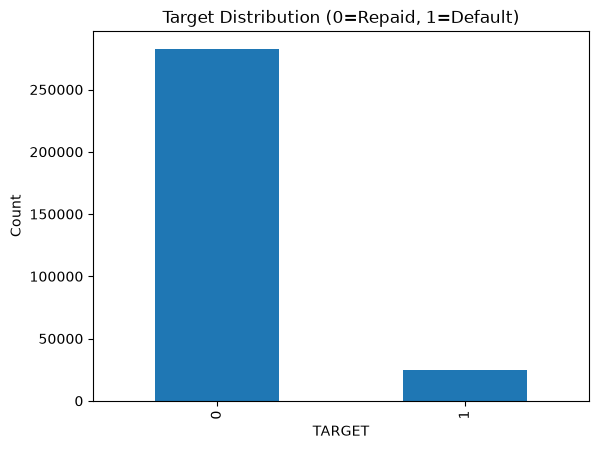

In [7]:
target_counts = df['TARGET'].value_counts() 
target_pct = df['TARGET'].value_counts(normalize=True) * 100

print("Class distribution:")
for cls in target_counts.index:
    print(f"  Class {cls}: {target_counts[cls]:,} ({target_pct[cls]:.2f}%)")

df['TARGET'].value_counts().plot(kind='bar', title='Target Distribution (0=Repaid, 1=Default)')
plt.ylabel('Count')
plt.show()


In [15]:
for col in categorical_cols:
    n_unique = df[col].nunique()
    print(f"{col}: {n_unique} unique values")

NAME_CONTRACT_TYPE: 2 unique values
CODE_GENDER: 3 unique values
FLAG_OWN_CAR: 2 unique values
FLAG_OWN_REALTY: 2 unique values
NAME_TYPE_SUITE: 7 unique values
NAME_INCOME_TYPE: 8 unique values
NAME_EDUCATION_TYPE: 5 unique values
NAME_FAMILY_STATUS: 6 unique values
NAME_HOUSING_TYPE: 6 unique values
OCCUPATION_TYPE: 18 unique values
WEEKDAY_APPR_PROCESS_START: 7 unique values
ORGANIZATION_TYPE: 58 unique values
FONDKAPREMONT_MODE: 4 unique values
HOUSETYPE_MODE: 3 unique values
WALLSMATERIAL_MODE: 7 unique values
EMERGENCYSTATE_MODE: 2 unique values


In [17]:
from sklearn.model_selection import train_test_split
X = df.drop(columns=['TARGET', 'SK_ID_CURR'])
y = df['TARGET']

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Train: {X_train.shape[0]} rows, Val: {X_val.shape[0]} rows")
print(f"Train target rate: {y_train.mean():.4f}")
print(f"Val target rate: {y_val.mean():.4f}")

Train: 246008 rows, Val: 61503 rows
Train target rate: 0.0807
Val target rate: 0.0807


In [18]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score

dummy = DummyClassifier(strategy='stratified', random_state=42)
dummy.fit(X_train.select_dtypes(exclude='object'), y_train)  # numeric-only for now, categoricals come next
dummy_preds = dummy.predict_proba(X_val.select_dtypes(exclude='object'))[:, 1]

print(f"Dummy baseline AUC: {roc_auc_score(y_val, dummy_preds):.4f}")

Dummy baseline AUC: 0.5016


In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline 
from sklearn.impute import SimpleImputer 
from sklearn.preprocessing import StandardScaler, OneHotEncoder


numeric_cols = X_train.select_dtypes(exclude='object').columns.tolist()

low_card_categorical = [
    'NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY',
    'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE',
    'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'WEEKDAY_APPR_PROCESS_START',
    'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE',
    'EMERGENCYSTATE_MODE', 'OCCUPATION_TYPE'
]

low_card_categorical = [
    'NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY',
    'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE',
    'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'WEEKDAY_APPR_PROCESS_START',
    'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE',
    'EMERGENCYSTATE_MODE', 'OCCUPATION_TYPE'
]

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])


# Categorical pipeline: fill missing with a placeholder category, then one-hot encode
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_cols),
    ('cat', categorical_transformer, low_card_categorical)
])

In [21]:
from sklearn.linear_model import LogisticRegression

logreg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'))
])

logreg_pipeline.fit(X_train, y_train)

logreg_preds = logreg_pipeline.predict_proba(X_val)[:, 1]
logreg_auc = roc_auc_score(y_val, logreg_preds)

print(f"Logistic Regression AUC: {logreg_auc:.4f}")
print(f"Improvement over dummy baseline: +{logreg_auc - 0.5016:.4f}")

Logistic Regression AUC: 0.7483
Improvement over dummy baseline: +0.2467


In [22]:
X_train_lgb = X_train.copy()
X_val_lgb = X_val.copy()

# Convert all categorical (object) columns to pandas 'category' dtype
# LightGBM reads this dtype natively and handles the encoding internally
categorical_features = X_train_lgb.select_dtypes(include='object').columns.tolist()

for col in categorical_features:
    X_train_lgb[col] = X_train_lgb[col].astype('category')
    X_val_lgb[col] = X_val_lgb[col].astype('category')

print(f"{len(categorical_features)} columns converted to category dtype")
print(categorical_features)

C:\Users\sacha\AppData\Local\Temp\ipykernel_57228\1379465653.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train_lgb.select_dtypes(include='object').columns.tolist()


16 columns converted to category dtype
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']


In [25]:
import lightgbm as lgb

lgb_model = lgb.LGBMClassifier(
    n_estimators=1000,
    learning_rate=0.03,
    num_leaves=31,
    min_child_samples=50,      # each leaf needs at least 50 samples — prevents overfitting to tiny noisy splits
    reg_alpha=0.1,              # L1 regularization — discourages unnecessary complexity
    reg_lambda=0.1,             # L2 regularization — same purpose, different mechanism
    subsample=0.8,              # each tree sees 80% of rows, randomly — reduces overfitting, adds robustness
    colsample_bytree=0.8,       # each tree sees 80% of columns, randomly — same purpose
    random_state=42,
    verbose=-1
)

lgb_model.fit(
    X_train_lgb, y_train,
    eval_set=[(X_val_lgb, y_val)],
    eval_metric='auc',
    categorical_feature=categorical_features,
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
)

print(f"Best iteration: {lgb_model.best_iteration_}")

c:\Users\sacha\credit-risk-project\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Best iteration: 531


In [26]:
lgb_preds = lgb_model.predict_proba(X_val_lgb)[:, 1]
lgb_auc = roc_auc_score(y_val, lgb_preds)

print(f"LightGBM AUC: {lgb_auc:.4f}")
print(f"\nModel comparison:")
print(f"  Dummy baseline:      0.5016")
print(f"  Logistic Regression: 0.7483")
print(f"  LightGBM:            {lgb_auc:.4f}")
print(f"  Improvement over logreg: +{lgb_auc - 0.7483:.4f}")

LightGBM AUC: 0.7618

Model comparison:
  Dummy baseline:      0.5016
  Logistic Regression: 0.7483
  LightGBM:            0.7618
  Improvement over logreg: +0.0135


                        feature  importance
38            ORGANIZATION_TYPE        1863
39                 EXT_SOURCE_1        1005
41                 EXT_SOURCE_3         979
40                 EXT_SOURCE_2         805
6                    AMT_CREDIT         676
15                   DAYS_BIRTH         610
7                   AMT_ANNUITY         603
16                DAYS_EMPLOYED         551
18              DAYS_ID_PUBLISH         530
93       DAYS_LAST_PHONE_CHANGE         511
8               AMT_GOODS_PRICE         510
17            DAYS_REGISTRATION         442
26              OCCUPATION_TYPE         387
19                  OWN_CAR_AGE         364
5              AMT_INCOME_TOTAL         363
14   REGION_POPULATION_RELATIVE         287
119  AMT_REQ_CREDIT_BUREAU_YEAR         203
31      HOUR_APPR_PROCESS_START         185
86               TOTALAREA_MODE         165
1                   CODE_GENDER         161


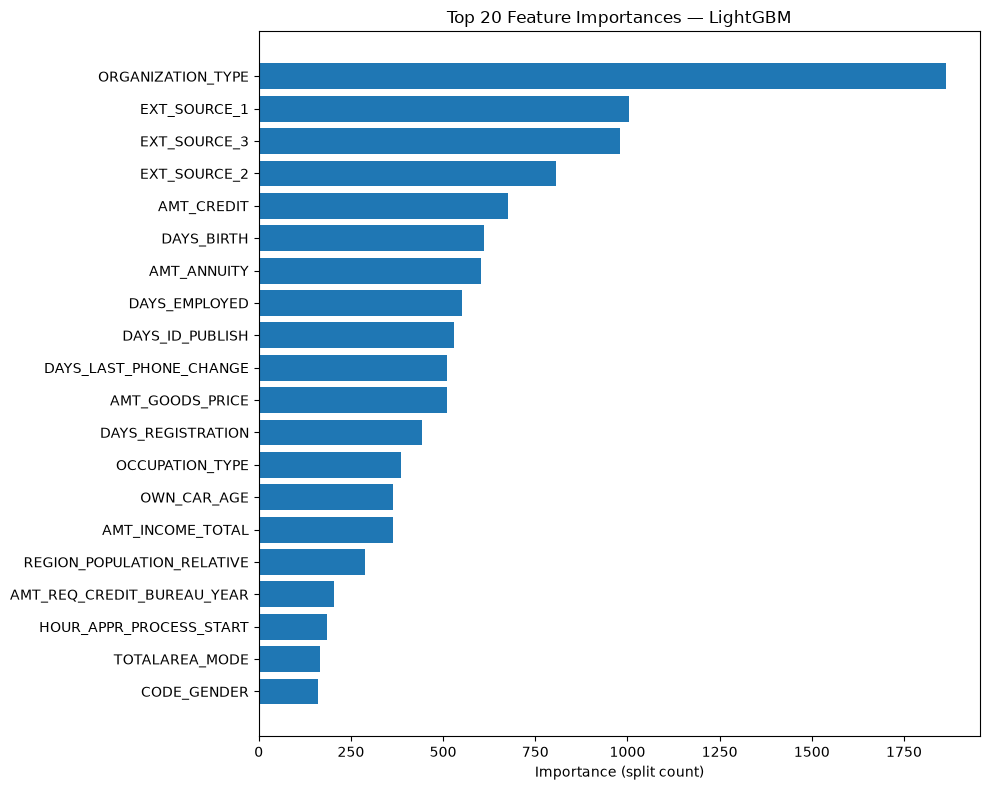

In [27]:
import pandas as pd

importance_df = pd.DataFrame({
    'feature': X_train_lgb.columns,
    'importance': lgb_model.feature_importances_
}).sort_values('importance', ascending=False)

print(importance_df.head(20))

plt.figure(figsize=(10, 8))
plt.barh(importance_df.head(20)['feature'][::-1], importance_df.head(20)['importance'][::-1])
plt.xlabel('Importance (split count)')
plt.title('Top 20 Feature Importances — LightGBM')
plt.tight_layout()
plt.show()

In [35]:
bureau = pd.read_csv('data/bureau.csv')

print (f"Shape: {bureau.shape}")
print(f"Unique applicants: {bureau['SK_ID_CURR'].nunique()}")
print(f"Rows per applicant: {len(bureau)/bureau['SK_ID_CURR'].nunique():.2f}")


Shape: (1716428, 17)
Unique applicants: 305811
Rows per applicant: 5.61


In [36]:
bureau.columns

Index(['SK_ID_CURR', 'SK_ID_BUREAU', 'CREDIT_ACTIVE', 'CREDIT_CURRENCY',
       'DAYS_CREDIT', 'CREDIT_DAY_OVERDUE', 'DAYS_CREDIT_ENDDATE',
       'DAYS_ENDDATE_FACT', 'AMT_CREDIT_MAX_OVERDUE', 'CNT_CREDIT_PROLONG',
       'AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM_LIMIT',
       'AMT_CREDIT_SUM_OVERDUE', 'CREDIT_TYPE', 'DAYS_CREDIT_UPDATE',
       'AMT_ANNUITY'],
      dtype='str')

In [40]:
bureau['CREDIT_ACTIVE'].value_counts()

CREDIT_ACTIVE
Closed      1079273
Active       630607
Sold           6527
Bad debt         21
Name: count, dtype: int64

In [41]:
bureau_agg = bureau.groupby('SK_ID_CURR').agg(
    bureau_count =('SK_ID_BUREAU','count'),
    bureau_active_count = ('CREDIT_ACTIVE', lambda x: (x == 'Active').sum()),
    bureau_days_credit_mean = ('DAYS_CREDIT','mean'),
    bureau_days_credit_min = ('DAYS_CREDIT','min'),
    bureau_credit_sum_total=('AMT_CREDIT_SUM', 'sum'),
    bureau_credit_sum_mean=('AMT_CREDIT_SUM', 'mean'),
    bureau_debt_sum_total=('AMT_CREDIT_SUM_DEBT', 'sum'),
    bureau_overdue_max=('CREDIT_DAY_OVERDUE', 'max'),
    bureau_overdue_mean=('CREDIT_DAY_OVERDUE', 'mean'),
).reset_index()


bureau_agg['bureau_debt_credit_ratio'] = (
    bureau_agg['bureau_debt_sum_total'] / bureau_agg['bureau_credit_sum_total'].replace(0, np.nan)
)

print(f"Aggregated Shape: {bureau_agg.shape}")
bureau_agg.head()


Aggregated Shape: (305811, 11)


,SK_ID_CURR,bureau_count,bureau_active_count,bureau_days_credit_mean,bureau_days_credit_min,bureau_credit_sum_total,bureau_credit_sum_mean,bureau_debt_sum_total,bureau_overdue_max,bureau_overdue_mean,bureau_debt_credit_ratio
0,100001,7,3,-735.000000,-1572,1453365.000,207623.571429,596686.5,0,0.0,0.410555
1,100002,8,2,-874.000000,-1437,865055.565,108131.945625,245781.0,0,0.0,0.284122
2,100003,4,1,-1400.750000,-2586,1017400.500,254350.125000,0.0,0,0.0,0.000000
3,100004,2,0,-867.000000,-1326,189037.800,94518.900000,0.0,0,0.0,0.000000
4,100005,3,2,-190.666667,-373,657126.000,219042.000000,568408.5,0,0.0,0.864992


In [43]:
X_full = df.drop(columns = ['TARGET'])
y = df['TARGET']

X_train, X_val, y_train, y_val = train_test_split(
    X_full, y, test_size=0.2, random_state=42, stratify=y
    )
print("Re-split complete, SK_ID_CURR retained for merging")



Re-split complete, SK_ID_CURR retained for merging


In [45]:
X_train_fe = X_train.merge(bureau_agg, on='SK_ID_CURR', how='left')
X_val_fe = X_val.merge(bureau_agg, on='SK_ID_CURR', how='left')

print(f"Before merge: {X_train.shape[1]} columns")
print(f"After merge: {X_train_fe.shape[1]} columns")

Before merge: 121 columns
After merge: 131 columns


In [46]:
categorical_features = X_train_fe.select_dtypes(include='object').columns.tolist()

for col in categorical_features:
    X_train_fe[col] = X_train_fe[col].astype('category')
    X_val_fe[col] = X_val_fe[col].astype('category')

print(f"{len(categorical_features)} categorical columns")

C:\Users\sacha\AppData\Local\Temp\ipykernel_57228\1695492534.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train_fe.select_dtypes(include='object').columns.tolist()


16 categorical columns


In [47]:
X_train_fe = X_train_fe.drop(columns=['SK_ID_CURR'])
X_val_fe = X_val_fe.drop(columns=['SK_ID_CURR'])

In [48]:
lgb_model_fe = lgb.LGBMClassifier(
    n_estimators=1000,
    learning_rate=0.03,
    num_leaves=31,
    min_child_samples=50,
    reg_alpha=0.1,
    reg_lambda=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    verbose=-1
)

lgb_model_fe.fit(
    X_train_fe, y_train,
    eval_set=[(X_val_fe, y_val)],
    eval_metric='auc',
    categorical_feature=categorical_features,
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
)

fe_preds = lgb_model_fe.predict_proba(X_val_fe)[:, 1]
fe_auc = roc_auc_score(y_val, fe_preds)

print(f"LightGBM AUC (with bureau features): {fe_auc:.4f}")
print(f"Previous (base features only):        0.7618")
print(f"Improvement:                          +{fe_auc - 0.7618:.4f}")

c:\Users\sacha\credit-risk-project\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


LightGBM AUC (with bureau features): 0.7649
Previous (base features only):        0.7618
Improvement:                          +0.0031


In [49]:
match_rate = X_train_fe['bureau_count'].notna().mean()
print(f"Applicants with bureau data: {match_rate:.2%}")

print(X_train_fe['bureau_count'].describe())

Applicants with bureau data: 85.67%
count    210764.000000
mean          5.557396
std           4.372630
min           1.000000
25%           2.000000
50%           4.000000
75%           8.000000
max          94.000000
Name: bureau_count, dtype: float64


In [50]:
importance_fe = pd.DataFrame({
    'feature': X_train_fe.columns,
    'importance': lgb_model_fe.feature_importances_
}).sort_values('importance', ascending=False)

bureau_features = [c for c in X_train_fe.columns if c.startswith('bureau_')]
print("Bureau feature rankings:")
print(importance_fe[importance_fe['feature'].isin(bureau_features)])

print("\nTop 15 overall:")
print(importance_fe.head(15))

Bureau feature rankings:
                      feature  importance
129  bureau_debt_credit_ratio         417
125    bureau_credit_sum_mean         366
122   bureau_days_credit_mean         321
124   bureau_credit_sum_total         293
121       bureau_active_count         292
126     bureau_debt_sum_total         282
123    bureau_days_credit_min         274
120              bureau_count         130
127        bureau_overdue_max          16
128       bureau_overdue_mean          14

Top 15 overall:
                      feature  importance
38          ORGANIZATION_TYPE        1744
39               EXT_SOURCE_1         818
40               EXT_SOURCE_2         729
41               EXT_SOURCE_3         669
15                 DAYS_BIRTH         560
6                  AMT_CREDIT         527
7                 AMT_ANNUITY         482
8             AMT_GOODS_PRICE         422
16              DAYS_EMPLOYED         420
129  bureau_debt_credit_ratio         417
18            DAYS_ID_PUBLISH     

In [51]:
print(bureau['CREDIT_DAY_OVERDUE'].describe())
print(f"\n% of records with zero overdue days: {(bureau['CREDIT_DAY_OVERDUE'] == 0).mean():.2%}")

count    1.716428e+06
mean     8.181666e-01
std      3.654443e+01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      2.792000e+03
Name: CREDIT_DAY_OVERDUE, dtype: float64

% of records with zero overdue days: 99.75%


In [52]:
prev_app = pd.read_csv('data/previous_application.csv')

print(f"Shape: {prev_app.shape}")
print(f"Unique applicants: {prev_app['SK_ID_CURR'].nunique()}")
prev_app['NAME_CONTRACT_STATUS'].value_counts()

Shape: (1670214, 37)
Unique applicants: 338857


NAME_CONTRACT_STATUS
Approved        1036781
Canceled         316319
Refused          290678
Unused offer      26436
Name: count, dtype: int64

In [56]:
prev_agg = prev_app.groupby("SK_ID_CURR").agg(
    prev_count=('SK_ID_PREV', 'count'),
    prev_approved_count=('NAME_CONTRACT_STATUS', lambda x: (x=='Approved').sum()),
    prev_refused_count=('NAME_CONTRACT_STATUS', lambda x: (x=='Refused').sum()),
    prev_canceled_count=('NAME_CONTRACT_STATUS', lambda x: (x=='Canceled').sum()),
    prev_amt_credit_mean= ('AMT_CREDIT', 'mean'),
    prev_amt_credit_max= ('AMT_CREDIT', 'max'),
    prev_amt_annuity_mean=('AMT_ANNUITY', 'mean'),
    prev_days_decision_mean=('DAYS_DECISION', 'mean'),
    prev_cnt_payment_mean=('CNT_PAYMENT', 'mean'),
).reset_index()

# Derived: refusal rate — how often this applicant has been turned down before, as a proportion
prev_agg['prev_refused_ratio'] = prev_agg['prev_refused_count'] / prev_agg['prev_count']

print(f"Aggregated shape: {prev_agg.shape}")
prev_agg.head()

Aggregated shape: (338857, 11)


,SK_ID_CURR,prev_count,prev_approved_count,prev_refused_count,prev_canceled_count,prev_amt_credit_mean,prev_amt_credit_max,prev_amt_annuity_mean,prev_days_decision_mean,prev_cnt_payment_mean,prev_refused_ratio
0,100001,1,1,0,0,23787.00,23787.0,3951.000,-1740.0,8.0,0.0
1,100002,1,1,0,0,179055.00,179055.0,9251.775,-606.0,24.0,0.0
2,100003,3,3,0,0,484191.00,1035882.0,56553.990,-1305.0,10.0,0.0
3,100004,1,1,0,0,20106.00,20106.0,5357.250,-815.0,4.0,0.0
4,100005,2,1,0,1,20076.75,40153.5,4813.200,-536.0,12.0,0.0


In [57]:
X_train_fe2 = X_train_fe.copy()
X_val_fe2 = X_val_fe.copy()

# Need SK_ID_CURR back temporarily for this merge — reload it from X_train/X_val (which still have it)
X_train_fe2['SK_ID_CURR'] = X_train['SK_ID_CURR'].values
X_val_fe2['SK_ID_CURR'] = X_val['SK_ID_CURR'].values

X_train_fe2 = X_train_fe2.merge(prev_agg, on='SK_ID_CURR', how='left').drop(columns=['SK_ID_CURR'])
X_val_fe2 = X_val_fe2.merge(prev_agg, on='SK_ID_CURR', how='left').drop(columns=['SK_ID_CURR'])

print(f"Before: {X_train_fe.shape[1]} columns, After: {X_train_fe2.shape[1]} columns")

lgb_model_fe2 = lgb.LGBMClassifier(
    n_estimators=1000, learning_rate=0.03, num_leaves=31,
    min_child_samples=50, reg_alpha=0.1, reg_lambda=0.1,
    subsample=0.8, colsample_bytree=0.8, random_state=42, verbose=-1
)

lgb_model_fe2.fit(
    X_train_fe2, y_train,
    eval_set=[(X_val_fe2, y_val)],
    eval_metric='auc',
    categorical_feature=categorical_features,
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
)

fe2_preds = lgb_model_fe2.predict_proba(X_val_fe2)[:, 1]
fe2_auc = roc_auc_score(y_val, fe2_preds)

print(f"LightGBM AUC (bureau + previous_application): {fe2_auc:.4f}")
print(f"Previous (bureau only):                        0.7649")
print(f"Improvement:                                    +{fe2_auc - 0.7649:.4f}")

Before: 130 columns, After: 140 columns


c:\Users\sacha\credit-risk-project\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


LightGBM AUC (bureau + previous_application): 0.7717
Previous (bureau only):                        0.7649
Improvement:                                    +0.0068


In [58]:
importance_fe2 = pd.DataFrame({
    'feature': X_train_fe2.columns,
    'importance': lgb_model_fe2.feature_importances_
}).sort_values('importance', ascending=False)

prev_features = [c for c in X_train_fe2.columns if c.startswith('prev_')]
print("Previous application feature rankings:")
print(importance_fe2[importance_fe2['feature'].isin(prev_features)])

print("\nTop 15 overall:")
print(importance_fe2.head(15))

Previous application feature rankings:
                     feature  importance
138    prev_cnt_payment_mean         454
136    prev_amt_annuity_mean         450
137  prev_days_decision_mean         402
135      prev_amt_credit_max         338
139       prev_refused_ratio         303
134     prev_amt_credit_mean         228
131      prev_approved_count         149
130               prev_count         114
132       prev_refused_count          69
133      prev_canceled_count          43

Top 15 overall:
                      feature  importance
38          ORGANIZATION_TYPE        1719
39               EXT_SOURCE_1         732
40               EXT_SOURCE_2         638
41               EXT_SOURCE_3         626
138     prev_cnt_payment_mean         454
15                 DAYS_BIRTH         453
136     prev_amt_annuity_mean         450
7                 AMT_ANNUITY         448
6                  AMT_CREDIT         443
137   prev_days_decision_mean         402
129  bureau_debt_credit_ratio  

In [59]:
installments = pd.read_csv('data/installments_payments.csv')

print(f"Shape: {installments.shape}")
print(f"Unique applicants: {installments['SK_ID_CURR'].nunique()}")
installments.head()

Shape: (13605401, 8)
Unique applicants: 339587


,SK_ID_PREV,SK_ID_CURR,NUM_INSTALMENT_VERSION,NUM_INSTALMENT_NUMBER,DAYS_INSTALMENT,DAYS_ENTRY_PAYMENT,AMT_INSTALMENT,AMT_PAYMENT
0,1054186,161674,1.0,6,-1180.0,-1187.0,6948.360,6948.360
1,1330831,151639,0.0,34,-2156.0,-2156.0,1716.525,1716.525
2,2085231,193053,2.0,1,-63.0,-63.0,25425.000,25425.000
3,2452527,199697,1.0,3,-2418.0,-2426.0,24350.130,24350.130
4,2714724,167756,1.0,2,-1383.0,-1366.0,2165.040,2160.585


In [60]:
# Positive = paid late, negative/zero = paid on time or early
installments['payment_delay'] = installments['DAYS_ENTRY_PAYMENT'] - installments['DAYS_INSTALMENT']

# Below 1.0 = underpaid that installment, 1.0 = paid exactly, above = overpaid
installments['payment_ratio'] = installments['AMT_PAYMENT'] / installments['AMT_INSTALMENT'].replace(0, np.nan)

install_agg = installments.groupby('SK_ID_CURR').agg(
    install_count=('SK_ID_CURR', 'count'),
    install_delay_mean=('payment_delay', 'mean'),
    install_delay_max=('payment_delay', 'max'),
    install_late_count=('payment_delay', lambda x: (x > 0).sum()),
    install_ratio_mean=('payment_ratio', 'mean'),
    install_ratio_min=('payment_ratio', 'min'),
).reset_index()

install_agg['install_late_ratio'] = install_agg['install_late_count'] / install_agg['install_count']

print(f"Aggregated shape: {install_agg.shape}")
install_agg.head()

Aggregated shape: (339587, 8)


,SK_ID_CURR,install_count,install_delay_mean,install_delay_max,install_late_count,install_ratio_mean,install_ratio_min,install_late_ratio
0,100001,7,-7.285714,11.0,1,1.0,1.0,0.142857
1,100002,19,-20.421053,-12.0,0,1.0,1.0,0.000000
2,100003,25,-7.160000,-1.0,0,1.0,1.0,0.000000
3,100004,3,-7.666667,-3.0,0,1.0,1.0,0.000000
4,100005,9,-23.555556,1.0,1,1.0,1.0,0.111111


In [61]:
X_train_fe3 = X_train_fe2.copy()
X_val_fe3 = X_val_fe2.copy()

X_train_fe3['SK_ID_CURR'] = X_train['SK_ID_CURR'].values
X_val_fe3['SK_ID_CURR'] = X_val['SK_ID_CURR'].values

X_train_fe3 = X_train_fe3.merge(install_agg, on='SK_ID_CURR', how='left').drop(columns=['SK_ID_CURR'])
X_val_fe3 = X_val_fe3.merge(install_agg, on='SK_ID_CURR', how='left').drop(columns=['SK_ID_CURR'])

print(f"Before: {X_train_fe2.shape[1]} columns, After: {X_train_fe3.shape[1]} columns")

lgb_model_fe3 = lgb.LGBMClassifier(
    n_estimators=1000, learning_rate=0.03, num_leaves=31,
    min_child_samples=50, reg_alpha=0.1, reg_lambda=0.1,
    subsample=0.8, colsample_bytree=0.8, random_state=42, verbose=-1
)

lgb_model_fe3.fit(
    X_train_fe3, y_train,
    eval_set=[(X_val_fe3, y_val)],
    eval_metric='auc',
    categorical_feature=categorical_features,
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
)

fe3_preds = lgb_model_fe3.predict_proba(X_val_fe3)[:, 1]
fe3_auc = roc_auc_score(y_val, fe3_preds)

print(f"LightGBM AUC (+ installments): {fe3_auc:.4f}")
print(f"Previous (bureau + prev_app):   0.7717")
print(f"Improvement:                    +{fe3_auc - 0.7717:.4f}")

Before: 140 columns, After: 147 columns


c:\Users\sacha\credit-risk-project\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


LightGBM AUC (+ installments): 0.7771
Previous (bureau + prev_app):   0.7717
Improvement:                    +0.0054


--Dummy baseline:                0.5016

--Logistic Regression:           0.7483

--LightGBM (base features):      0.7618
+ bureau.csv:                  0.7649  (+0.0031)
+ previous_application.csv:    0.7717  (+0.0068)
+ installments_payments.csv:   0.7771  (+0.0054)

In [62]:
importance_fe3 = pd.DataFrame({
    'feature': X_train_fe3.columns,
    'importance': lgb_model_fe3.feature_importances_
}).sort_values('importance', ascending=False)

install_features = [c for c in X_train_fe3.columns if c.startswith('install_')]
print("Installments feature rankings:")
print(importance_fe3[importance_fe3['feature'].isin(install_features)])

print("\nTop 15 overall:")
print(importance_fe3.head(15))

Installments feature rankings:
                feature  importance
141  install_delay_mean         524
140       install_count         492
146  install_late_ratio         469
142   install_delay_max         450
144  install_ratio_mean         325
145   install_ratio_min         206
143  install_late_count         143

Top 15 overall:
                      feature  importance
38          ORGANIZATION_TYPE        2320
39               EXT_SOURCE_1         930
40               EXT_SOURCE_2         808
41               EXT_SOURCE_3         803
137   prev_days_decision_mean         723
136     prev_amt_annuity_mean         674
15                 DAYS_BIRTH         672
6                  AMT_CREDIT         626
138     prev_cnt_payment_mean         618
7                 AMT_ANNUITY         599
16              DAYS_EMPLOYED         546
125    bureau_credit_sum_mean         544
129  bureau_debt_credit_ratio         536
18            DAYS_ID_PUBLISH         529
141        install_delay_mean     

In [63]:
pos_cash = pd.read_csv('data/POS_CASH_balance.csv')
credit_card = pd.read_csv('data/credit_card_balance.csv')

print(f"POS_CASH: {pos_cash.shape}, {pos_cash['SK_ID_CURR'].nunique()} applicants")
print(f"credit_card: {credit_card.shape}, {credit_card['SK_ID_CURR'].nunique()} applicants")

pos_agg = pos_cash.groupby('SK_ID_CURR').agg(
    pos_count=('SK_ID_CURR', 'count'),
    pos_dpd_mean=('SK_DPD', 'mean'),        # DPD = Days Past Due
    pos_dpd_max=('SK_DPD', 'max'),
    pos_cnt_installment_mean=('CNT_INSTALMENT', 'mean'),
).reset_index()

cc_agg = credit_card.groupby('SK_ID_CURR').agg(
    cc_count=('SK_ID_CURR', 'count'),
    cc_balance_mean=('AMT_BALANCE', 'mean'),
    cc_balance_max=('AMT_BALANCE', 'max'),
    cc_credit_limit_mean=('AMT_CREDIT_LIMIT_ACTUAL', 'mean'),
    cc_dpd_mean=('SK_DPD', 'mean'),
    cc_drawings_atm_mean=('AMT_DRAWINGS_ATM_CURRENT', 'mean'),
).reset_index()

# Utilization ratio: how much of their available credit limit they're actually using
cc_agg['cc_utilization'] = cc_agg['cc_balance_mean'] / cc_agg['cc_credit_limit_mean'].replace(0, np.nan)

print(f"pos_agg shape: {pos_agg.shape}, cc_agg shape: {cc_agg.shape}")

POS_CASH: (10001358, 8), 337252 applicants
credit_card: (3840312, 23), 103558 applicants
pos_agg shape: (337252, 5), cc_agg shape: (103558, 8)


In [64]:
X_train_fe4 = X_train_fe3.copy()
X_val_fe4 = X_val_fe3.copy()

X_train_fe4['SK_ID_CURR'] = X_train['SK_ID_CURR'].values
X_val_fe4['SK_ID_CURR'] = X_val['SK_ID_CURR'].values

for agg_table in [pos_agg, cc_agg]:
    X_train_fe4 = X_train_fe4.merge(agg_table, on='SK_ID_CURR', how='left')
    X_val_fe4 = X_val_fe4.merge(agg_table, on='SK_ID_CURR', how='left')

X_train_fe4 = X_train_fe4.drop(columns=['SK_ID_CURR'])
X_val_fe4 = X_val_fe4.drop(columns=['SK_ID_CURR'])

print(f"Before: {X_train_fe3.shape[1]} columns, After: {X_train_fe4.shape[1]} columns")

lgb_model_fe4 = lgb.LGBMClassifier(
    n_estimators=1000, learning_rate=0.03, num_leaves=31,
    min_child_samples=50, reg_alpha=0.1, reg_lambda=0.1,
    subsample=0.8, colsample_bytree=0.8, random_state=42, verbose=-1
)

lgb_model_fe4.fit(
    X_train_fe4, y_train,
    eval_set=[(X_val_fe4, y_val)],
    eval_metric='auc',
    categorical_feature=categorical_features,
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
)

fe4_preds = lgb_model_fe4.predict_proba(X_val_fe4)[:, 1]
fe4_auc = roc_auc_score(y_val, fe4_preds)

print(f"LightGBM AUC (all 5 tables): {fe4_auc:.4f}")
print(f"Previous (3 tables):          0.7771")
print(f"Improvement:                  +{fe4_auc - 0.7771:.4f}")

Before: 147 columns, After: 158 columns


c:\Users\sacha\credit-risk-project\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


LightGBM AUC (all 5 tables): 0.7810
Previous (3 tables):          0.7771
Improvement:                  +0.0039


In [65]:
importance_fe4 = pd.DataFrame({
    'feature': X_train_fe4.columns,
    'importance': lgb_model_fe4.feature_importances_
}).sort_values('importance', ascending=False)

pos_cc_features = [c for c in X_train_fe4.columns if c.startswith('pos_') or c.startswith('cc_')]
print("POS_CASH / credit_card feature rankings:")
print(importance_fe4[importance_fe4['feature'].isin(pos_cc_features)])

print("\nTop 15 overall:")
print(importance_fe4.head(15))

POS_CASH / credit_card feature rankings:
                      feature  importance
150  pos_cnt_installment_mean         394
147                 pos_count         369
157            cc_utilization         239
156      cc_drawings_atm_mean         229
151                  cc_count         105
153            cc_balance_max          99
154      cc_credit_limit_mean          98
148              pos_dpd_mean          89
152           cc_balance_mean          88
149               pos_dpd_max          58
155               cc_dpd_mean          56

Top 15 overall:
                      feature  importance
38          ORGANIZATION_TYPE        1703
39               EXT_SOURCE_1         653
41               EXT_SOURCE_3         614
40               EXT_SOURCE_2         581
15                 DAYS_BIRTH         454
6                  AMT_CREDIT         420
7                 AMT_ANNUITY         414
150  pos_cnt_installment_mean         394
138     prev_cnt_payment_mean         389
136     prev_amt_a

In [68]:
import optuna
from sklearn.model_selection import StratifiedKFold

# Prepare the final feature set (X_train_fe4 + X_val_fe4 combined, since CV will do its own splitting)
X_full_fe = pd.concat([X_train_fe4, X_val_fe4], axis=0).reset_index(drop=True)
y_full = pd.concat([y_train, y_val], axis=0).reset_index(drop=True)

X_full_fe = pd.concat([X_train_fe4, X_val_fe4], axis=0).reset_index(drop=True)
y_full = pd.concat([y_train, y_val], axis=0).reset_index(drop=True)

# Re-cast categoricals — concat can silently drop the 'category' dtype back to object
for col in categorical_features:
    X_full_fe[col] = X_full_fe[col].astype('category')

print(f"Full feature set for CV: {X_full_fe.shape}")
print(X_full_fe[categorical_features].dtypes.value_counts())  # sanity check — should show all 'category'
print(f"Full feature set for CV: {X_full_fe.shape}")

def objective(trial):
    params = {
        'n_estimators': 1000,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 15, 63),
        'min_child_samples': trial.suggest_int('min_child_samples', 20, 100),
        'reg_alpha': trial.suggest_float('reg_alpha', 0.001, 1.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 0.001, 1.0, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'random_state': 42,
        'verbose': -1,
    }

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    fold_scores = []

    for train_idx, val_idx in skf.split(X_full_fe, y_full):
        X_tr, X_vl = X_full_fe.iloc[train_idx], X_full_fe.iloc[val_idx]
        y_tr, y_vl = y_full.iloc[train_idx], y_full.iloc[val_idx]

        model = lgb.LGBMClassifier(**params)
        model.fit(
            X_tr, y_tr,
            eval_set=[(X_vl, y_vl)],
            eval_metric='auc',
            categorical_feature=categorical_features,
            callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
        )
        preds = model.predict_proba(X_vl)[:, 1]
        fold_scores.append(roc_auc_score(y_vl, preds))

    return np.mean(fold_scores)

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30)

print(f"Best AUC (5-fold CV mean): {study.best_value:.4f}")
print(f"Best params: {study.best_params}")

[I 2026-09-25 20:18:00,333] A new study created in memory with name: no-name-c5769a59-3b19-4279-a47b-f86d6ee3d51b


Full feature set for CV: (307511, 158)
category    2
category    1
category    1
category    1
category    1
category    1
category    1
category    1
category    1
category    1
category    1
category    1
category    1
category    1
category    1
Name: count, dtype: int64
Full feature set for CV: (307511, 158)


c:\Users\sacha\credit-risk-project\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\sacha\credit-risk-project\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\sacha\credit-risk-project\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\sacha\credit-risk-project\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _valida

KeyboardInterrupt: 

In [69]:
print(f"Completed trials: {len(study.trials)}")
print(f"Best AUC so far: {study.best_value:.4f}")
print(f"Best params so far: {study.best_params}")

Completed trials: 12
Best AUC so far: 0.7803
Best params so far: {'learning_rate': 0.04420031474370418, 'num_leaves': 35, 'min_child_samples': 98, 'reg_alpha': 0.8623359835809192, 'reg_lambda': 0.28645776818552166, 'subsample': 0.7932766438503013, 'colsample_bytree': 0.6569752465950212}


In [70]:
X_tune, _, y_tune, _ = train_test_split(
    X_full_fe, y_full, train_size=80000, stratify=y_full, random_state=42
)

def objective(trial):
    params = {
        'n_estimators': 500,
        'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.08, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 20, 50),
        'min_child_samples': trial.suggest_int('min_child_samples', 50, 120),
        'reg_alpha': trial.suggest_float('reg_alpha', 0.05, 1.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 0.05, 1.0, log=True),
        'subsample': trial.suggest_float('subsample', 0.7, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 0.9),
        'random_state': 42,
        'verbose': -1,
    }

    skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    fold_scores = []

    for train_idx, val_idx in skf.split(X_tune, y_tune):
        X_tr, X_vl = X_tune.iloc[train_idx], X_tune.iloc[val_idx]
        y_tr, y_vl = y_tune.iloc[train_idx], y_tune.iloc[val_idx]

        model = lgb.LGBMClassifier(**params)
        model.fit(
            X_tr, y_tr,
            eval_set=[(X_vl, y_vl)],
            eval_metric='auc',
            categorical_feature=categorical_features,
            callbacks=[lgb.early_stopping(stopping_rounds=30, verbose=False)]
        )
        preds = model.predict_proba(X_vl)[:, 1]
        fold_scores.append(roc_auc_score(y_vl, preds))

    return np.mean(fold_scores)

study2 = optuna.create_study(direction='maximize')
study2.optimize(objective, n_trials=25, show_progress_bar=True)

print(f"Best AUC (subsample, refined search): {study2.best_value:.4f}")
print(f"Best params: {study2.best_params}")

[I 2026-09-25 22:10:04,038] A new study created in memory with name: no-name-b6dae8f0-70b7-454f-9a4f-a14411b21fbc


  0%|          | 0/25 [00:00<?, ?it/s]

c:\Users\sacha\credit-risk-project\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\sacha\credit-risk-project\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\sacha\credit-risk-project\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[I 2026-09-25 22:11:25,365] Trial 0 finished with value: 0.7644559680261264 and parameters: {'learning_rate': 0.030848769771055672, 'num_leaves': 20, 'min_child_samples': 94, 'reg_alpha': 0.06775938583922428, 'reg_lambda': 0.08493110939852076, 'subsample': 0.7022812961596907, 'colsample_bytree': 0.6845585230958833}. Best is trial 0 with value: 0.7644559680261264.


c:\Users\sacha\credit-risk-project\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\sacha\credit-risk-project\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\sacha\credit-risk-project\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


...

[I 2026-09-25 22:33:10,563] Trial 22 finished with value: 0.7653861368860321 and parameters: {'learning_rate': 0.02951218876262815, 'num_leaves': 38, 'min_child_samples': 119, 'reg_alpha': 0.5066808571536638, 'reg_lambda': 0.18193204615310585, 'subsample': 0.7299712232400356, 'colsample_bytree': 0.6272631824049364}. Best is trial 22 with value: 0.7653861368860321.


c:\Users\sacha\credit-risk-project\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\sacha\credit-risk-project\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\sacha\credit-risk-project\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[I 2026-09-25 22:33:50,934] Trial 23 finished with value: 0.7641374473378861 and parameters: {'learning_rate': 0.0380305121347174, 'num_leaves': 36, 'min_child_samples': 120, 'reg_alpha': 0.4690978170443977, 'reg_lambda': 0.10532132568225554, 'subsample': 0.7282649798888936, 'colsample_bytree': 0.6542285976323694}. Best is trial 22 with value: 0.7653861368860321.


c:\Users\sacha\credit-risk-project\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\sacha\credit-risk-project\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\sacha\credit-risk-project\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[I 2026-09-25 22:34:34,628] Trial 24 finished with value: 0.7647242561041203 and parameters: {'learning_rate': 0.03319946606999767, 'num_leaves': 28, 'min_child_samples': 119, 'reg_alpha': 0.7497738315444613, 'reg_lambda': 0.15661949521548912, 'subsample': 0.756937181923661, 'colsample_bytree': 0.6488640738184912}. Best is trial 22 with value: 0.7653861368860321.
Best AUC (subsample, refined search): 0.7654
Best params: {'learning_rate': 0.02951218876262815, 'num_leaves': 38, 'min_child_samples': 119, 'reg_alpha': 0.5066808571536638, 'reg_lambda': 0.18193204615310585, 'subsample': 0.7299712232400356, 'colsample_bytree': 0.6272631824049364}


In [71]:
best_params = study2.best_params
best_params.update({'n_estimators': 1000, 'random_state': 42, 'verbose': -1})

lgb_model_final = lgb.LGBMClassifier(**best_params)

lgb_model_final.fit(
    X_train_fe4, y_train,
    eval_set=[(X_val_fe4, y_val)],
    eval_metric='auc',
    categorical_feature=categorical_features,
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
)

final_preds = lgb_model_final.predict_proba(X_val_fe4)[:, 1]
final_auc = roc_auc_score(y_val, final_preds)

print(f"Tuned model AUC (full data, same val split as before): {final_auc:.4f}")
print(f"Previous best (untuned hyperparameters):                 0.7810")
print(f"Improvement:                                              +{final_auc - 0.7810:.4f}")
print(f"\nBest iteration: {lgb_model_final.best_iteration_}")

c:\Users\sacha\credit-risk-project\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Tuned model AUC (full data, same val split as before): 0.7819
Previous best (untuned hyperparameters):                 0.7810
Improvement:                                              +0.0009

Best iteration: 737


In [72]:
print("=" * 50)
print("FINAL MODEL SUMMARY")
print("=" * 50)
print(f"Dummy baseline:                    0.5016")
print(f"Logistic Regression:               0.7483")
print(f"LightGBM (base features):          0.7618")
print(f"+ bureau.csv:                       0.7649")
print(f"+ previous_application.csv:         0.7717")
print(f"+ installments_payments.csv:        0.7771")
print(f"+ POS_CASH + credit_card:           0.7810")
print(f"+ hyperparameter tuning:            0.7819  <- FINAL")
print("=" * 50)
print(f"Total improvement over dummy baseline: +{0.7819 - 0.5016:.4f}")
print(f"Total improvement over logistic regression: +{0.7819 - 0.7483:.4f}")

FINAL MODEL SUMMARY
Dummy baseline:                    0.5016
Logistic Regression:               0.7483
LightGBM (base features):          0.7618
+ bureau.csv:                       0.7649
+ previous_application.csv:         0.7717
+ installments_payments.csv:        0.7771
+ POS_CASH + credit_card:           0.7810
+ hyperparameter tuning:            0.7819  <- FINAL
Total improvement over dummy baseline: +0.2803
Total improvement over logistic regression: +0.0336


In [73]:
import shap

# SHAP's TreeExplainer is optimized specifically for tree-based models like LightGBM — fast, exact (not approximated)
explainer = shap.TreeExplainer(lgb_model_final)

# Computing SHAP values for the full validation set can be slow; start with a sample
shap_sample = X_val_fe4.sample(n=2000, random_state=42)
shap_values = explainer.shap_values(shap_sample)

print(f"SHAP values shape: {shap_values.shape}")

SHAP values shape: (2000, 158)


c:\Users\sacha\credit-risk-project\venv\Lib\site-packages\shap\explainers\_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


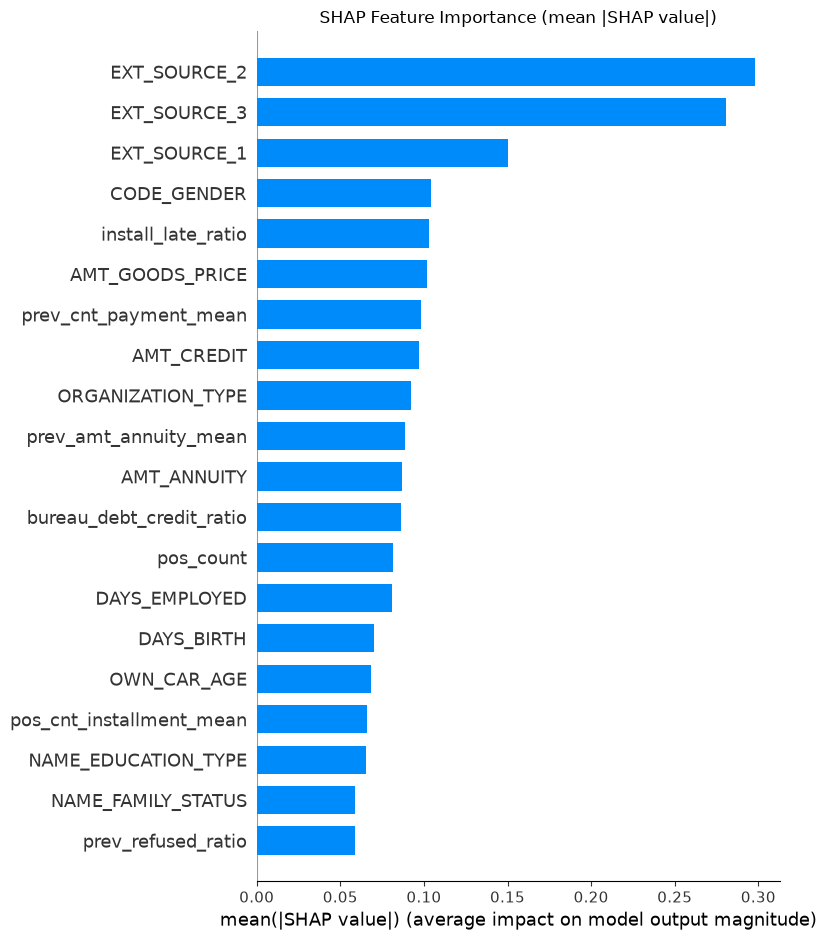

In [74]:
shap.summary_plot(shap_values, shap_sample, plot_type='bar', show=False)
plt.title('SHAP Feature Importance (mean |SHAP value|)')
plt.tight_layout()
plt.savefig('shap_importance_bar.png', dpi=150)
plt.show()

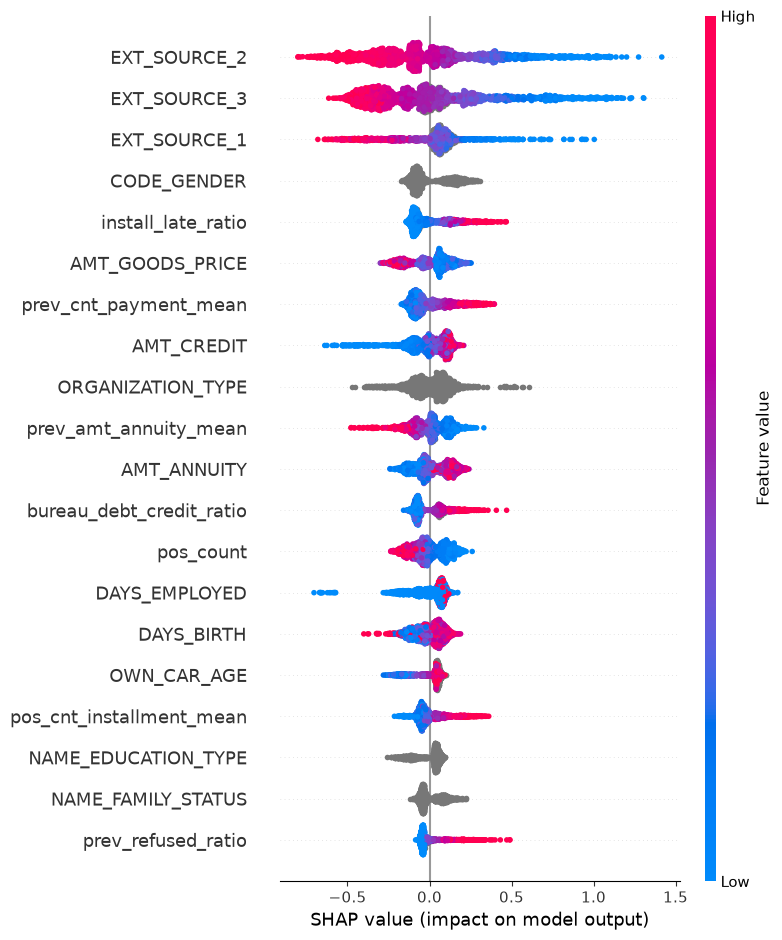

In [75]:
shap.summary_plot(shap_values, shap_sample, show=False)
plt.tight_layout()
plt.savefig('shap_summary_detailed.png', dpi=150)
plt.show()

In [78]:
print((X_val_fe4['DAYS_EMPLOYED'] == 365243).sum())
print(f"As % of validation set: {(X_val_fe4['DAYS_EMPLOYED'] == 365243).mean():.2%}")

11231
As % of validation set: 18.26%


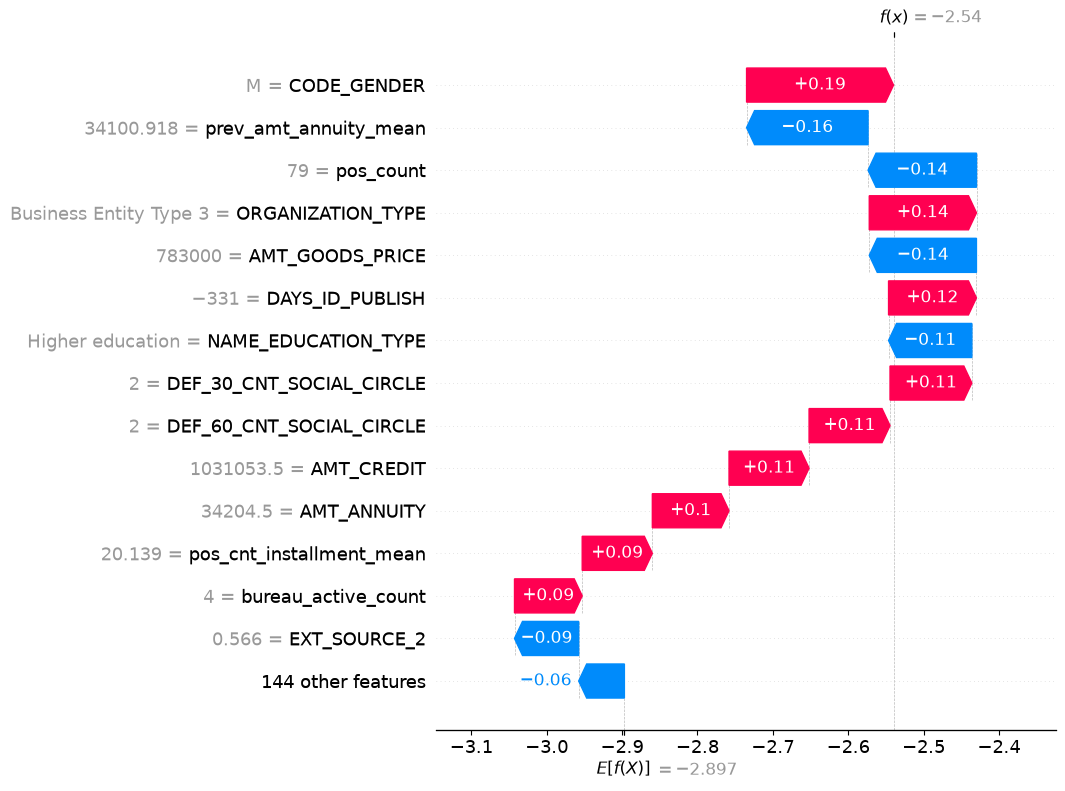

<Figure size 640x480 with 0 Axes>

In [79]:
# Pick one applicant from the validation sample
idx = 0  # first row of shap_sample — change this to explore others

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[idx],
        base_values=explainer.expected_value,
        data=shap_sample.iloc[idx],
        feature_names=shap_sample.columns.tolist()
    ),
    max_display=15
)
plt.tight_layout()
plt.savefig('shap_waterfall_example.png', dpi=150)
plt.show()

In [80]:
# Create a flag for the anomaly BEFORE fixing it, since the anomaly itself may be informative
# (e.g., correlates with retirement/unemployment status)
for df_ in [X_train_fe4, X_val_fe4]:
    df_['is_days_employed_anomaly'] = (df_['DAYS_EMPLOYED'] == 365243).astype(int)
    df_.loc[df_['DAYS_EMPLOYED'] == 365243, 'DAYS_EMPLOYED'] = np.nan  # let LightGBM handle it as a true missing value

In [81]:
protected_features = ['CODE_GENDER']

X_train_fair = X_train_fe4.drop(columns=protected_features)
X_val_fair = X_val_fe4.drop(columns=protected_features)

categorical_features_fair = [c for c in categorical_features if c not in protected_features]

lgb_model_fair = lgb.LGBMClassifier(**{k: v for k, v in best_params.items()})
lgb_model_fair.fit(
    X_train_fair, y_train,
    eval_set=[(X_val_fair, y_val)],
    eval_metric='auc',
    categorical_feature=categorical_features_fair,
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
)

fair_preds = lgb_model_fair.predict_proba(X_val_fair)[:, 1]
fair_auc = roc_auc_score(y_val, fair_preds)

print(f"AUC without CODE_GENDER: {fair_auc:.4f}")
print(f"AUC with CODE_GENDER:    0.7819")
print(f"Cost of fairness fix:    {fair_auc - 0.7819:.4f}")

c:\Users\sacha\credit-risk-project\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


AUC without CODE_GENDER: 0.7793
AUC with CODE_GENDER:    0.7819
Cost of fairness fix:    -0.0026


In [82]:
import joblib

joblib.dump(lgb_model_fair, 'model.pkl')
joblib.dump(categorical_features_fair, 'categorical_features.pkl')

# Save the exact column order the model expects — critical for correct predictions later
joblib.dump(X_train_fair.columns.tolist(), 'feature_columns.pkl')

print("Model and artifacts saved")

Model and artifacts saved


In [83]:
# Run this in your notebook to generate the boilerplate for you
for col, dtype in X_train_fair.dtypes.items():
    py_type = 'str' if dtype == 'category' else ('int' if dtype == 'int64' else 'float')
    print(f"    {col}: {py_type}")

    NAME_CONTRACT_TYPE: str
    FLAG_OWN_CAR: str
    FLAG_OWN_REALTY: str
    CNT_CHILDREN: int
    AMT_INCOME_TOTAL: float
    AMT_CREDIT: float
    AMT_ANNUITY: float
    AMT_GOODS_PRICE: float
    NAME_TYPE_SUITE: str
    NAME_INCOME_TYPE: str
    NAME_EDUCATION_TYPE: str
    NAME_FAMILY_STATUS: str
    NAME_HOUSING_TYPE: str
    REGION_POPULATION_RELATIVE: float
    DAYS_BIRTH: int
    DAYS_EMPLOYED: float
    DAYS_REGISTRATION: float
    DAYS_ID_PUBLISH: int
    OWN_CAR_AGE: float
    FLAG_MOBIL: int
    FLAG_EMP_PHONE: int
    FLAG_WORK_PHONE: int
    FLAG_CONT_MOBILE: int
    FLAG_PHONE: int
    FLAG_EMAIL: int
    OCCUPATION_TYPE: str
    CNT_FAM_MEMBERS: float
    REGION_RATING_CLIENT: int
    REGION_RATING_CLIENT_W_CITY: int
    WEEKDAY_APPR_PROCESS_START: str
    HOUR_APPR_PROCESS_START: int
    REG_REGION_NOT_LIVE_REGION: int
    REG_REGION_NOT_WORK_REGION: int
    LIVE_REGION_NOT_WORK_REGION: int
    REG_CITY_NOT_LIVE_CITY: int
    REG_CITY_NOT_WORK_CITY: int
    LIVE_CIT